<a href="https://colab.research.google.com/github/cxm042828-dot/2026.10.28/blob/main/AI_xun_lian_ji.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TensorFlow 버전: 2.21.0
apple 데이터 다운로드 중...
apple: 2000개 로드 완료
bicycle 데이터 다운로드 중...
bicycle: 2000개 로드 완료
cat 데이터 다운로드 중...
cat: 2000개 로드 완료
house 데이터 다운로드 중...
house: 2000개 로드 완료
star 데이터 다운로드 중...
star: 2000개 로드 완료
전체 데이터 형태: (10000, 28, 28, 1)
전체 라벨 형태: (10000,)
학습 데이터: (8000, 28, 28, 1)
테스트 데이터: (2000, 28, 28, 1)


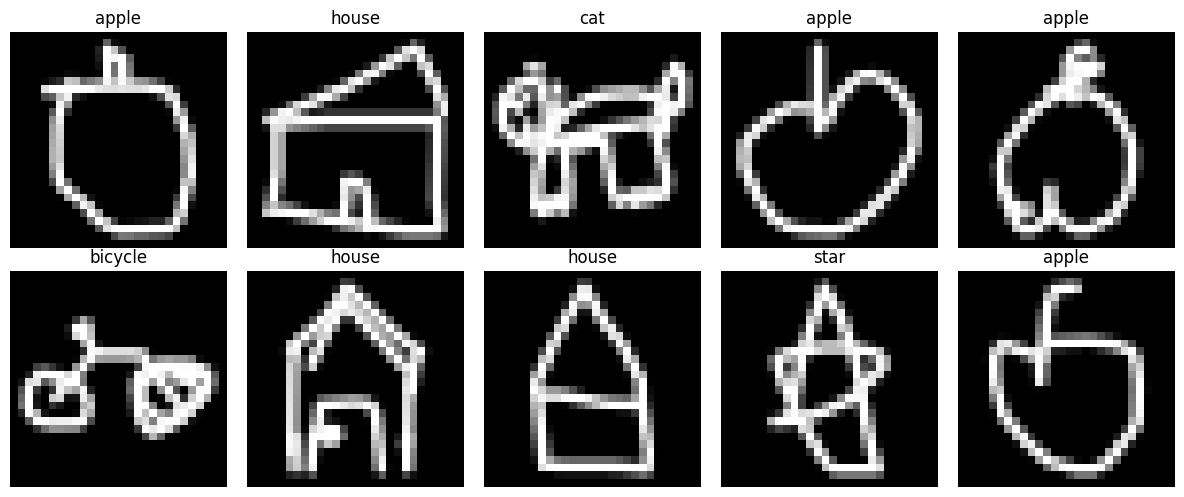

第一类：数据集导入与预处理完成！


In [5]:
# ============================================
# 1. 라이브러리 불러오기
# ============================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import os

from sklearn.model_selection import train_test_split

print("TensorFlow 버전:", tf.__version__)


# ============================================
# 2. 공개 데이터셋 다운로드
# ============================================

categories = ['apple', 'bicycle', 'cat', 'house', 'star']

SAMPLES_PER_CLASS = 2000

os.makedirs('/content/quickdraw', exist_ok=True)

X_list = []
y_list = []

for label, category in enumerate(categories):

    print(f"{category} 데이터 다운로드 중...")

    url = (
        "https://storage.googleapis.com/"
        "quickdraw_dataset/full/numpy_bitmap/"
        + category + ".npy"
    )

    file_path = f"/content/quickdraw/{category}.npy"

    if not os.path.exists(file_path):
        urllib.request.urlretrieve(url, file_path)

    data = np.load(file_path)

    data = data[:SAMPLES_PER_CLASS]

    X_list.append(data)
    y_list.append(np.full(len(data), label))

    print(f"{category}: {len(data)}개 로드 완료")


# ============================================
# 3. 데이터 통합 및 전처리
# ============================================

X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

X = X.reshape(-1, 28, 28, 1)

X = X.astype('float32') / 255.0

print("전체 데이터 형태:", X.shape)
print("전체 라벨 형태:", y.shape)


# ============================================
# 4. 학습 데이터와 테스트 데이터 분리
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)


# ============================================
# 5. 데이터 샘플 시각화
# ============================================

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_train[i].squeeze(),
        cmap='gray'
    )

    plt.title(categories[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

print("第一类：数据集导入与预处理完成！")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 224,389 (876.52 KB)

 Trainable params: 224,389 (876.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 225ms/step - accuracy: 0.7397 - loss: 0.7186 - val_accuracy: 0.8938 - val_loss: 0.3503
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 113ms/step - accuracy: 0.8900 - loss: 0.3368 - val_accuracy: 0.9281 - val_loss: 0.2317
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - accuracy: 0.9206 - loss: 0.2368 - val_accuracy: 0.9394 - val_loss: 0.1919
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 132ms/step - accuracy: 0.9361 - loss: 0.1928 - val_accuracy: 0.9456 - val_loss: 0.1682
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 116ms/step - accuracy: 0.9489 - loss: 0.1631 - val_accuracy: 0.9531 - val_loss: 0.1550
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 149ms/step - accuracy: 0.9498 - loss: 0.1475 - val_accuracy: 0.9531 - val_loss: 0.1460
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.9572 - loss: 0.1313 - val_accuracy: 0.9538 - val_loss: 0.1497
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 135ms/step - accuracy: 0.9619 - loss: 0.1192 - val_accuracy

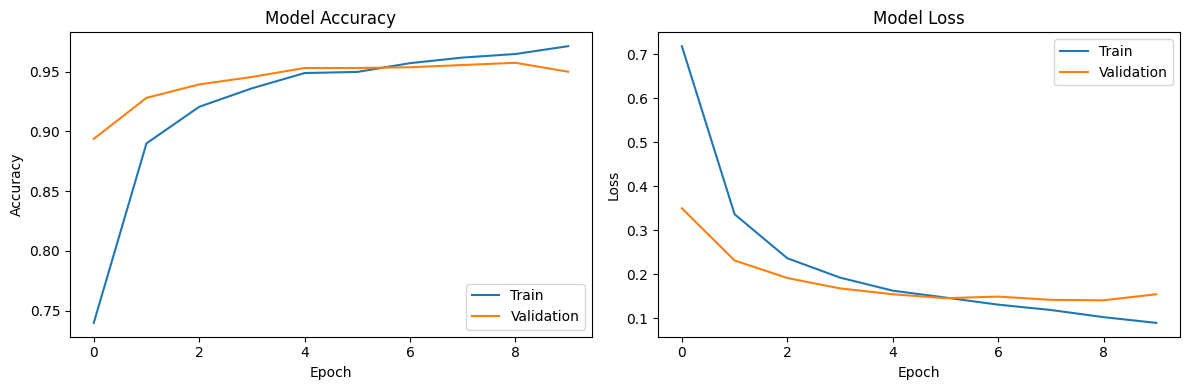

AI 모델 저장 완료!
第二类：AI 模型训练完成！


In [4]:
# ============================================
# 1. CNN 모델 구축
# ============================================

from tensorflow.keras import layers, models

model = models.Sequential([

    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        32, (3, 3),
        activation='relu'
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation='relu'
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(
        len(categories),
        activation='softmax'
    )
])


# ============================================
# 2. 모델 컴파일
# ============================================

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


# ============================================
# 3. 모델 학습
# ============================================

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)


# ============================================
# 4. 모델 평가
# ============================================

test_loss, test_acc = model.evaluate(
    X_test,
    y_test,
    verbose=2
)

print(f"테스트 정확도: {test_acc * 100:.2f}%")


# ============================================
# 5. 학습 결과 시각화
# ============================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# ============================================
# 6. 모델 저장
# ============================================

model.save('/content/quickdraw_model.keras')

print("AI 모델 저장 완료!")
print("第二类：AI 模型训练完成！")

In [6]:
# ============================================
# 1. 라이브러리 불러오기
# ============================================

import base64
import re
import numpy as np

from PIL import Image
from io import BytesIO

from google.colab import output
from IPython.display import display, HTML


# ============================================
# 2. 이미지 전처리 및 예측 함수
# ============================================

def predict_drawing(data_url):

    image_data = re.sub(
        '^data:image/.+;base64,',
        '',
        data_url
    )

    image_bytes = base64.b64decode(image_data)

    img = Image.open(
        BytesIO(image_bytes)
    ).convert('L')

    img_array = np.array(img)

    coords = np.where(img_array > 20)

    if len(coords[0]) == 0:
        return "그림을 먼저 그려주세요."

    y_min, y_max = coords[0].min(), coords[0].max()
    x_min, x_max = coords[1].min(), coords[1].max()

    img = img.crop((
        x_min,
        y_min,
        x_max + 1,
        y_max + 1
    ))

    img.thumbnail(
        (20, 20),
        Image.Resampling.LANCZOS
    )

    new_img = Image.new(
        'L',
        (28, 28),
        0
    )

    x_offset = (28 - img.width) // 2
    y_offset = (28 - img.height) // 2

    new_img.paste(
        img,
        (x_offset, y_offset)
    )

    input_data = np.array(
        new_img,
        dtype=np.float32
    ) / 255.0

    input_data = input_data.reshape(
        1, 28, 28, 1
    )

    predictions = model.predict(
        input_data,
        verbose=0
    )[0]

    predicted_index = np.argmax(predictions)

    predicted_class = categories[predicted_index]

    confidence = predictions[predicted_index] * 100

    top3 = np.argsort(predictions)[-3:][::-1]

    result = (
        f"AI 예측 결과: {predicted_class.upper()}"
        f" ({confidence:.2f}%)\n"
    )

    result += "\n상위 3개 예측 결과:\n"

    for index in top3:

        result += (
            f"{categories[index]}: "
            f"{predictions[index] * 100:.2f}%\n"
        )

    return result


# ============================================
# 3. Python 함수 등록
# ============================================

output.register_callback(
    'notebook.predict_drawing',
    predict_drawing
)


# ============================================
# 4. HTML5 Canvas 그림판
# ============================================

html_code = """

<div style="
    max-width:600px;
    margin:auto;
    text-align:center;
    font-family:Arial,sans-serif;
">

    <h2>🎨 AI 그림 맞히기 게임</h2>

    <p>
        사과, 자전거, 고양이, 집, 별 중 하나를 그려보세요!
    </p>

    <p style="color:#777;font-size:14px;">
        그림을 그린 후 AI에게 맞혀보세요.
    </p>

    <canvas id="drawCanvas"
        width="280"
        height="280"
        style="
            border:3px solid #555;
            background:black;
            cursor:crosshair;
            touch-action:none;
            border-radius:8px;
        ">
    </canvas>

    <br><br>

    <button onclick="predictDrawing()"
        style="
            padding:12px 25px;
            font-size:16px;
            background:#1976D2;
            color:white;
            border:none;
            border-radius:8px;
            cursor:pointer;
        ">
        🤖 AI에게 물어보기
    </button>

    <button onclick="clearCanvas()"
        style="
            padding:12px 25px;
            font-size:16px;
            background:#757575;
            color:white;
            border:none;
            border-radius:8px;
            cursor:pointer;
        ">
        지우기
    </button>

    <div id="result"
        style="
            margin-top:20px;
            padding:20px;
            background:#f1f3f5;
            color:#222;
            border-radius:10px;
            font-size:17px;
            line-height:1.8;
            white-space:pre-line;
        ">
        그림을 그린 후 AI에게 물어보세요!
    </div>

</div>


<script>

const canvas = document.getElementById('drawCanvas');

const ctx = canvas.getContext('2d');

ctx.fillStyle = 'black';

ctx.fillRect(0, 0, canvas.width, canvas.height);

ctx.strokeStyle = 'white';

ctx.lineWidth = 18;

ctx.lineCap = 'round';

ctx.lineJoin = 'round';

let drawing = false;


function getPosition(e) {

    const rect = canvas.getBoundingClientRect();

    return {
        x: (e.clientX - rect.left)
            * canvas.width / rect.width,

        y: (e.clientY - rect.top)
            * canvas.height / rect.height
    };
}


canvas.addEventListener('pointerdown', function(e) {

    drawing = true;

    canvas.setPointerCapture(e.pointerId);

    const pos = getPosition(e);

    ctx.beginPath();

    ctx.moveTo(pos.x, pos.y);

    ctx.lineTo(pos.x, pos.y);

    ctx.stroke();

});


canvas.addEventListener('pointermove', function(e) {

    if (!drawing) return;

    const pos = getPosition(e);

    ctx.lineTo(pos.x, pos.y);

    ctx.stroke();

});


canvas.addEventListener('pointerup', function() {

    drawing = false;

});

canvas.addEventListener('pointercancel', function() {

    drawing = false;

});


function clearCanvas() {

    ctx.fillStyle = 'black';

    ctx.fillRect(
        0, 0,
        canvas.width,
        canvas.height
    );

    document.getElementById('result').innerText =
        '그림을 그린 후 AI에게 물어보세요!';

}


async function predictDrawing() {

    const resultDiv = document.getElementById('result');

    resultDiv.innerText =
        '🤖 AI가 그림을 분석하고 있습니다...';

    const imageData = canvas.toDataURL('image/png');

    try {

        const response = await google.colab.kernel.invokeFunction(
            'notebook.predict_drawing',
            [imageData],
            {}
        );

        const result = response.data['text/plain'];

        resultDiv.innerText =
            String(result).replace(/^['"]|['"]$/g, '');

    }

    catch(error) {

        resultDiv.innerText =
            '오류가 발생했습니다: ' + error.message;

    }

}

</script>

"""

display(HTML(html_code))

print("第三类：AI 预测交互界面加载完成！")

第三类：AI 预测交互界面加载完成！
